# Base 14 – Empresa de Mineração
## Notebook 1 – Dados, limpeza, análise estatística e agrupamento

**Projeto Integrador – Engenharia de Computação – FHO – 6º semestre**

Este é o primeiro de dois notebooks:

| Notebook | Tópicos |
|---|---|
| **1 (este)** | 1. Os dados e o problema · 2. Limpeza de dados · 3. Análise estatística · 4. Agrupamento (não supervisionado) |
| 2 (`02_Series_Temporais_Base14.ipynb`) | 5. Análise de séries temporais |

O roteiro segue o material do professor `Estatistica_Pos_Wrangling_e_Nao_Supervisionado_EngComp.ipynb`, citado como **[E nº]**. O material é uma referência, não uma lista obrigatória [E 91]: cada técnica usada aqui responde uma pergunta do grupo, e as técnicas sem pergunta ficaram de fora.

### Sumário
1. Os dados e o problema
2. Limpeza de dados
3. Análise estatística
4. Agrupamento e técnicas não supervisionadas
5. Conclusões

## 1. Os dados e o problema

### 1.1 Contexto

A base representa a operação de uma **empresa de mineração de ferro** com 6 minas em MG, GO, MS e PA. O ciclo de cada operação é:

1. a **escavadeira** extrai o minério em uma **frente de lavra**;
2. o **caminhão** transporta o minério até a usina;
3. a **usina** processa o minério e separa o **produto** (minério de ferro concentrado) do **rejeito**.

Cada registro guarda a qualidade do minério (teores de ferro e sílica, umidade, granulometria), as massas em cada etapa, o transporte (distância, ciclo, viagens, diesel), o tempo (horas de operação e paradas), as falhas e a manutenção, os custos, a produtividade e a emissão de CO2.

**Problema de negócio:** entender o que afeta a **produtividade**, o **custo**, a **qualidade** e as **restrições operacionais**. O objetivo é apoiar decisões como escala de turnos, manutenção dos equipamentos e planejamento de lavra.

### 1.2 Ambiente e carregamento

No Google Colab todas as bibliotecas já estão instaladas. Fora do Colab: `pip install pandas numpy scipy statsmodels scikit-learn matplotlib seaborn`. No Colab, enviar os arquivos `base_14_empresa_mineracao_limpa.csv` e `base_14_empresa_mineracao_original.csv` para a sessão (ou montar o Drive).

In [1]:
import sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy, statsmodels, sklearn
from scipy import stats
from scipy.cluster.hierarchy import linkage, dendrogram
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score)

SEED = 42
warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.float_format', '{:,.3f}'.format)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 4)
for nome, mod in [('python', sys), ('pandas', pd), ('numpy', np), ('scipy', scipy),
                  ('statsmodels', statsmodels), ('scikit-learn', sklearn)]:
    print(f"{nome:12s} {getattr(mod, '__version__', sys.version.split()[0])}")

python       3.14.7
pandas       3.0.6
numpy        2.5.3
scipy        1.18.1
statsmodels  0.15.0
scikit-learn 1.9.1


In [2]:
CAMINHO = 'base_14_empresa_mineracao_limpa.csv'
df = pd.read_csv(CAMINHO, sep=';', encoding='utf-8-sig', parse_dates=['data_operacao'])
df = df.sort_values('data_operacao').reset_index(drop=True)
# Variável derivada: custo operacional por tonelada de produto final
df['custo_por_t'] = df['custo_operacional_rs'] / df['massa_produto_t']
print(df.shape)
df.head()

(9850, 42)


,registro_id,data_operacao,mina,estado,frente_lavra,turno,tipo_minerio,equipamento_escavacao,equipamento_transporte,operador_id,...,produtividade_t_h,emissao_co2_kg,indice_qualidade_minerio,status_operacao,operacao_com_restricao,ano_operacao,mes_operacao,dia_semana_operacao,dias_desde_inicio,custo_por_t
0,REG-0000106,2025-01-01,Mina Serra Norte,PA,F02,Manhã,Magnetita,ESC-02,CAM-101,OP-2136,...,154.640,250.930,84.500,Operação normal,0,2025,1,2,0,17.444
1,REG-0005715,2025-01-01,Mina Catalão,GO,F01,Tarde,Itabirito,ESC-02,CAM-105,OP-1105,...,129.850,150.720,73.000,Operação normal,0,2025,1,2,0,27.055
2,REG-0001173,2025-01-01,Mina Brucutu,MG,F05,Noite,Itabirito,ESC-04,CAM-108,OP-2126,...,130.110,207.240,66.200,Operação com restrição,1,2025,1,2,0,40.669
3,REG-0001511,2025-01-01,Mina Brucutu,MG,F02,Tarde,Minério misto,ESC-03,CAM-103,OP-2170,...,165.210,391.170,83.200,Operação normal,0,2025,1,2,0,13.379
4,REG-0006951,2025-01-01,Mina Corumbá,MS,F06,Tarde,Magnetita,ESC-05,CAM-101,OP-1168,...,154.030,247.720,94.100,Operação normal,0,2025,1,2,0,25.275


### 1.3 Dicionário de dados [E 4]

| Coluna | Significado | Unidade / valores |
|---|---|---|
| `registro_id` | identificador da operação | texto único |
| `data_operacao` | dia da operação | data (01/2025 a 08/2026) |
| `mina`, `estado` | mina e estado (cada mina pertence a um só estado) | 6 minas, 4 estados |
| `frente_lavra` | frente de lavra dentro da mina | F01 a F06 |
| `turno` | turno de trabalho | Manhã, Tarde, Noite |
| `tipo_minerio` | tipo de minério lavrado | Hematita, Itabirito, Magnetita, Minério misto |
| `equipamento_escavacao` | escavadeira | ESC-01 a ESC-05 |
| `equipamento_transporte` | caminhão | CAM-101 a CAM-108 |
| `operador_id` | operador | 1.497 operadores |
| `teor_fe_pct`, `teor_si_pct` | teor de ferro e de sílica no minério | % |
| `umidade_minerio_pct` | umidade do minério | % |
| `granulometria_media_mm` | tamanho médio das partículas | mm |
| `massa_extraida_t`, `massa_processada_t`, `massa_produto_t` | massa em cada etapa (extraída ≥ processada ≥ produto) | t |
| `recuperacao_metalurgica_pct` | produto ÷ processada × 100 | % |
| `rejeito_gerado_t` | material descartado na usina | t |
| `distancia_transporte_km`, `tempo_ciclo_min`, `qtd_viagens` | transporte | km, min, viagens |
| `consumo_diesel_l`, `consumo_diesel_estimado_l` | diesel real e estimado pela empresa | L |
| `consumo_energia_kwh` | energia elétrica | kWh |
| `horas_operacao`, `horas_parada` | tempo trabalhando e parado | h |
| `qtd_falhas_equipamento` | falhas na operação | 0 a 4 |
| `horas_desde_manutencao` | horas desde a última manutenção | h |
| `custo_manutencao_rs`, `custo_operacional_rs`, `custo_operacional_estimado_rs` | custos real e estimado | R$ |
| `produtividade_t_h` | toneladas por hora de operação | t/h |
| `emissao_co2_kg` | emissão de CO2 | kg |
| `indice_qualidade_minerio` | índice de qualidade | 0 a 100 |
| `status_operacao` | situação da operação | normal, com restrição, crítica |
| `operacao_com_restricao` | 1 se o status não é normal (criada na limpeza) | 0/1 |
| `ano_operacao`, `mes_operacao`, `dia_semana_operacao`, `dias_desde_inicio` | atributos de data criados na limpeza (dia da semana: 0 = segunda) | números |
| `custo_por_t` | custo operacional ÷ massa de produto (criada neste notebook) | R$/t |

### 1.4 Unidade de observação e desenho [E 1, E 6]

**O que é cada linha:** **uma operação de lavra**, ou seja, um turno em uma frente de lavra, com um operador, uma escavadeira e um caminhão.

**Cuidado com pseudorreplicação [E 6]:** as linhas não são totalmente independentes. O mesmo caminhão, a mesma escavadeira e a mesma mina aparecem milhares de vezes. Com tantas linhas por grupo, até diferenças pequenas ficam "significativas". Por isso todo teste vem acompanhado do **tamanho do efeito** em unidades do problema (t/h, R$/t).

In [3]:
print('Período:', df['data_operacao'].min().date(), 'a', df['data_operacao'].max().date())
dias = pd.date_range(df['data_operacao'].min(), df['data_operacao'].max(), freq='D')
print('Dias no calendário:', len(dias), '| dias com operação:', df['data_operacao'].nunique())
print('Operações por dia: média %.1f' % df.groupby('data_operacao').size().mean())
for c in ['mina', 'frente_lavra', 'turno', 'tipo_minerio', 'equipamento_escavacao',
          'equipamento_transporte', 'operador_id']:
    print(f'{c:24s} {df[c].nunique():5d} categorias')

Período: 2025-01-01 a 2026-08-31
Dias no calendário: 608 | dias com operação: 608
Operações por dia: média 16.2
mina                         6 categorias
frente_lavra                 6 categorias
turno                        3 categorias
tipo_minerio                 4 categorias
equipamento_escavacao        5 categorias
equipamento_transporte       8 categorias
operador_id               1497 categorias


**Interpretação e decisão**

A base limpa tem 9.850 operações em 608 dias corridos (01/01/2025 a 31/08/2026), **sem nenhum dia faltando**. São cerca de 16 operações por dia, com volume estável ao longo dos meses. Isso permite tratar os dados como série temporal diária no notebook 2.

Cada operador tem em média só 6,6 operações (1.497 operadores). Isso limita qualquer conclusão por operador (seção 4.6). Já minas, turnos, tipos de minério e equipamentos têm centenas ou milhares de operações cada, o suficiente para comparações.

### 1.5 Perguntas do grupo e técnicas escolhidas [E 7]

Primeiro o grupo listou o que quer saber sobre a operação. Depois escolheu, no material, a técnica que responde cada pergunta.

| # | Pergunta | Família | Técnica (seção do material) |
|---|----------|---------|------------------------------|
| P1 | Como se distribuem produtividade, custo por tonelada, recuperação e horas paradas? | Descrição | Centro, dispersão, quantis, histogramas [E 8–14] |
| P2 | Qual a frequência de operação crítica e qual a incerteza dessa proporção? | Inferência | Intervalo de Wilson [E 22] |
| P3 | A produtividade muda entre turnos? | Inferência | Levene, ANOVA de Welch, Kruskal-Wallis, pós-teste Holm, Hedges g [E 24, 27, 33–35] |
| P4 | A produtividade muda entre minas? | Inferência | Kruskal-Wallis [E 35] |
| P5 | Operação com restrição custa mais por tonelada? Quanto? | Inferência | Welch, Hedges g, Mann-Whitney [E 26–28] |
| P6 | A restrição depende do turno ou do tipo de minério? | Associação | Qui-quadrado e V de Cramér [E 38] |
| P7 | Quais variáveis andam juntas? Há redundância? | Associação | Matriz de Spearman [E 43–44] |
| P8 | Teor de Fe/Si, umidade e granulometria explicam a recuperação metalúrgica? | Modelagem | Regressão múltipla com erros HC3 [E 45–47] |
| P9 | Horas desde a manutenção aumentam o número de falhas? | Modelagem | Regressão de Poisson [E 53] |
| P10 | A estimativa de diesel da empresa tem viés? | Inferência | Teste t de uma amostra [E 25] |
| P11 | Existem perfis de operação sem usar rótulos? | Não supervisionado | Padronização, PCA, K-means, cotovelo e silhueta, estabilidade [E 60–65, 70–72, 80–81] |
| P12 | Algum equipamento tem padrão de desgaste diferente? | Não supervisionado | Agrupamento hierárquico [E 74] |
| P13 | Há operadores bons e pouco utilizados? (analogia do jogador subaproveitado) | Não supervisionado | Perfis por operador |
| P14 | Quais operações são incomuns? | Anomalias | Isolation Forest [E 85] |

As perguntas P15 a P18, sobre o comportamento ao longo do tempo, estão no notebook 2.

**Seções do material que ficaram de fora, e por quê:**
- E30, E31, E36 e E40 (testes pareados, Friedman, McNemar): exigem as mesmas unidades medidas antes e depois, e a base não tem esse desenho.
- E54–E58 (modelos mistos, MANOVA, poder, bayesiano, dados censurados): são avançados e não respondem nenhuma pergunta acima.
- E66–E69 (análise fatorial, SVD de texto, NMF, ICA): a base não tem texto nem sinais misturados.
- E73, E77, E79 e E83–E84 (MiniBatch, OPTICS/HDBSCAN, espectral, t-SNE/UMAP): K-means e hierárquico já respondem P11 e P12, e a base é pequena.

## 2. Limpeza de dados

A limpeza completa, com todo o código, está no notebook `Limpeza_de_Dados_Base14_Mineracao.ipynb`. Aqui ela é **explicada**: quais problemas a base original tinha, o que foi feito com cada um e por quê. Depois vem a verificação final da base limpa [E 5].

### 2.1 Problemas encontrados na base original

A base original é lida com todas as colunas como texto. Assim nenhuma conversão automática esconde um problema.

In [4]:
orig = pd.read_csv('base_14_empresa_mineracao_original.csv', sep=';', dtype=str, encoding='utf-8-sig')
print(f'Base original: {orig.shape[0]} linhas, {orig.shape[1]} colunas')
print(f'Linhas duplicadas inteiras: {orig.duplicated().sum()}')
print()
for c in ['turno', 'tipo_minerio', 'status_operacao']:
    print(f'{c}: {orig[c].nunique()} grafias diferentes -> {df[c].nunique()} categorias na base limpa')
    print('   exemplos:', orig[c].dropna().unique()[:10].tolist())
print()
print('Custos operacionais no formato "R$ 30.037,21":',
      orig['custo_operacional_rs'].str.contains('R$', regex=False, na=False).sum())
partes = orig['data_operacao'].str.split('/', expand=True).astype(int)
print('Datas que só existem no formato americano (mês/dia/ano, ex.: 07/30/2025):', (partes[1] > 12).sum())
print('   (datas ambíguas, como 03/05/2025, foram checadas na limpeza pelo período da base)')

Base original: 10000 linhas, 36 colunas


Linhas duplicadas inteiras: 150

turno: 12 grafias diferentes -> 3 categorias na base limpa
   exemplos: ['Manhã', 'Tarde', 'Noite', 'MANHA', 'manha', 'noite', 'Noite ', 'TARDE', 'Tarde ', 'Manha ']
tipo_minerio: 16 grafias diferentes -> 4 categorias na base limpa
   exemplos: ['Minério misto', 'Hematita', 'Magnetita', 'Itabirito', 'Misto', 'HEMATITA', 'Mag.', 'ITABIRITO', 'minerio misto', 'itabirito']
status_operacao: 9 grafias diferentes -> 3 categorias na base limpa
   exemplos: ['Operação normal', 'Normal', 'Operação com restrição', 'operacao normal', 'OPERAÇÃO COM RESTRIÇÃO', 'OPERAÇÃO NORMAL', 'Operação crítica', 'operacao com restricao', 'Restrição']

Custos operacionais no formato "R$ 30.037,21": 149
Datas que só existem no formato americano (mês/dia/ano, ex.: 07/30/2025): 45
   (datas ambíguas, como 03/05/2025, foram checadas na limpeza pelo período da base)


In [5]:
def para_numero(serie):
    return pd.to_numeric(serie.str.replace('R$', '', regex=False).str.replace(' ', ''), errors='coerce')

REGRAS = {'teor_fe_pct': ('acima de 72% (máximo físico do Fe)', lambda x: x > 72),
          'umidade_minerio_pct': ('acima de 30%', lambda x: x > 30),
          'indice_qualidade_minerio': ('acima de 100', lambda x: x > 100),
          'recuperacao_metalurgica_pct': ('acima de 100%', lambda x: x > 100),
          'distancia_transporte_km': ('negativa', lambda x: x < 0),
          'consumo_diesel_l': ('negativo', lambda x: x < 0),
          'horas_desde_manutencao': ('negativa', lambda x: x < 0)}
pd.DataFrame({c: {'valor impossível': texto,
                  'qtd na original': int(regra(para_numero(orig[c])).sum()),
                  'vazios na original': int(orig[c].isna().sum()),
                  'vazios na limpa': int(df[c].isna().sum())}
              for c, (texto, regra) in REGRAS.items()}).T

,valor impossível,qtd na original,vazios na original,vazios na limpa
teor_fe_pct,acima de 72% (máximo físico do Fe),14,95,107
umidade_minerio_pct,acima de 30%,12,131,141
indice_qualidade_minerio,acima de 100,7,150,157
recuperacao_metalurgica_pct,acima de 100%,12,108,0
distancia_transporte_km,negativa,10,0,10
consumo_diesel_l,negativo,10,124,132
horas_desde_manutencao,negativa,10,0,9


### 2.2 O que foi feito com cada problema

| Problema | O que foi feito | Por quê |
|---|---|---|
| Linhas duplicadas | Removidas | A mesma operação contada duas vezes distorce médias e contagens |
| Mesma categoria escrita de vários jeitos (`Manhã`, `MANHA`, `manha `, `Hem.`, `Itab.`…) | Texto padronizado (sem acento, minúsculo, sem espaço) e mapeado por um dicionário para o nome correto | Sem isso, "Manhã" e "MANHA" seriam turnos diferentes |
| Custo no formato `R$ 30.037,21` | Removido `R$` e ponto de milhar; vírgula trocada por ponto | O Python só entende número no formato `30037.21` |
| Datas em formato americano | Tentado `dd/mm/aaaa`; se falha, `mm/dd/aaaa` | Recupera a data sem perder a linha |
| Valores fisicamente impossíveis (teor de Fe > 72%, distância negativa…) | Transformados em vazio | Limites definidos pelo processo de mineração, não pela distribuição dos dados. Um valor impossível é erro de registro |
| Recuperação metalúrgica vazia ou acima de 100% | **Recalculada** pelas massas (produto ÷ processada × 100) | É uma conta exata; recalcular é melhor que inventar um valor |
| Demais vazios (cerca de 1% por coluna) | **Mantidos vazios** na base limpa | Preencher com média ou mediana inventaria dados. Cada análise decide como tratar seus vazios |
| Coluna `status_operacao` em texto | Criada `operacao_com_restricao` (0/1) | Alvo binário para a etapa de machine learning |
| Data em texto | Criados ano, mês, dia da semana e dias desde o início | Permite analisar o efeito do calendário |

### 2.3 Verificação final da base limpa [E 5]

In [6]:
contrato = pd.DataFrame({'tipo': df.dtypes.astype(str),
                         'vazios': df.isna().sum(),
                         'vazios_%': (df.isna().mean() * 100).round(2),
                         'distintos': df.nunique()})
display(contrato[contrato['vazios'] > 0])

assert df['registro_id'].is_unique, 'registro_id repetido'
assert set(df['turno'].dropna()) == {'Manhã', 'Tarde', 'Noite'}
assert df['teor_fe_pct'].dropna().between(0, 72).all()
assert df['recuperacao_metalurgica_pct'].between(0, 100).all()
assert (df['massa_produto_t'] <= df['massa_processada_t']).all()
assert (df['massa_processada_t'] <= df['massa_extraida_t']).all()
print(f'Base limpa: {df.shape[0]} linhas. Todas as verificações passaram.')

,tipo,vazios,vazios_%,distintos
tipo_minerio,str,118,1.200,4
equipamento_escavacao,str,100,1.020,5
equipamento_transporte,str,109,1.110,8
teor_fe_pct,float64,107,1.090,2903
teor_si_pct,float64,113,1.150,2134
umidade_minerio_pct,float64,141,1.430,1522
distancia_transporte_km,float64,10,0.100,1122
consumo_diesel_l,float64,132,1.340,6767
consumo_energia_kwh,float64,137,1.390,8967
horas_desde_manutencao,float64,9,0.090,2147


Base limpa: 9850 linhas. Todas as verificações passaram.


**Interpretação e decisão**

A base original tinha 10.000 linhas e problemas típicos de digitação e de integração de sistemas:
- **150 linhas duplicadas**, removidas (restam 9.850);
- **categorias escritas de vários jeitos**: 12 grafias de turno viraram 3, 16 de tipo de minério viraram 4 e 9 de status viraram 3;
- **149 custos com `R$`** e **datas em formato americano**, convertidos sem perder linhas;
- **valores impossíveis** (ex.: teor de Fe acima de 72%, distância negativa), transformados em vazio.

A recuperação metalúrgica tinha vazios e valores acima de 100%. Ela foi **recalculada pelas massas** e hoje não tem nenhum vazio.

As demais colunas ainda têm de 0,1% a 1,6% de vazios. A decisão foi **não preencher na base limpa**, para não inventar dados. Cada análise trata os vazios do seu jeito: os testes usam só as linhas com valor, e o agrupamento preenche com a mediana. As verificações finais confirmam: IDs únicos, categorias corretas, teores no limite físico e balanço de massa respeitado (produto ≤ processada ≤ extraída).

### 2.4 Preparação para machine learning (próxima etapa)

O notebook de limpeza também gerou as matrizes `dados_prontos_ml_treino.csv` e `dados_prontos_ml_teste.csv`, com:
- divisão treino/teste 80/20, estratificada pelo alvo;
- valores extremos limitados a ±3 desvios, com limites aprendidos só no treino;
- vazios preenchidos com mediana (números) e moda (categorias), também aprendidas só no treino;
- one-hot encoding das categorias (35 para 61 colunas) e padronização.

Essas matrizes não são usadas neste notebook. A análise abaixo encontrou dois cuidados para a etapa de ML:
1. `operacao_com_restricao` é calculada direto de `qtd_falhas_equipamento` (seção 3.7). Usar falhas como entrada seria vazamento de dados.
2. A divisão aleatória serve para classificação, mas **não** para série temporal. No notebook 2 a divisão é por data.

## 3. Análise estatística

**Parte descritiva:** o que é típico, quanto varia e como os grupos se comparam.

### 3.1 Frequências e composição [E 8] – P1

In [7]:
for c in ['status_operacao', 'turno', 'tipo_minerio', 'mina']:
    t = df[c].value_counts(dropna=False).to_frame('n')
    t['%'] = (t['n'] / len(df) * 100).round(2)
    display(t)

,n,%
status_operacao,,
Operação normal,7186,72.950
Operação com restrição,2650,26.900
Operação crítica,14,0.140


,n,%
turno,,
Manhã,3729,37.860
Tarde,3504,35.570
Noite,2617,26.570


,n,%
tipo_minerio,,
Hematita,3741,37.980
Itabirito,3095,31.420
Magnetita,1547,15.710
Minério misto,1349,13.700
NaN,118,1.200


,n,%
mina,,
Mina Brucutu,1670,16.950
Mina Azul,1667,16.920
Mina Corumbá,1649,16.740
Mina Serra Norte,1642,16.670
Mina Catalão,1619,16.440
Mina Itabira,1603,16.270


### 3.2 Centro, dispersão e caudas [E 9–11, E 13] – P1

O coeficiente de variação (CV) compara a dispersão entre variáveis de unidades diferentes. IQR e MAD são medidas robustas a extremos.

In [8]:
VARS = ['produtividade_t_h', 'custo_por_t', 'recuperacao_metalurgica_pct', 'horas_parada',
        'qtd_falhas_equipamento', 'teor_fe_pct', 'massa_produto_t', 'consumo_diesel_l', 'tempo_ciclo_min']
def resumo(s):
    s = s.dropna()
    return pd.Series({'n': len(s), 'media': s.mean(), 'mediana': s.median(), 'desvio': s.std(),
                      'CV_%': s.std() / s.mean() * 100, 'p05': s.quantile(.05), 'p95': s.quantile(.95),
                      'IQR': s.quantile(.75) - s.quantile(.25), 'MAD': stats.median_abs_deviation(s),
                      'assimetria': s.skew(), 'curtose': s.kurt()})
pd.DataFrame({v: resumo(df[v]) for v in VARS}).T

,n,media,mediana,desvio,CV_%,p05,p95,IQR,MAD,assimetria,curtose
produtividade_t_h,"9,850.000",175.860,173.740,29.983,17.049,130.983,227.750,41.947,20.795,0.203,-0.134
custo_por_t,"9,850.000",17.928,15.573,12.032,67.111,6.487,38.138,12.337,5.986,5.684,101.547
recuperacao_metalurgica_pct,"9,850.000",89.286,89.520,5.592,6.263,80.014,98.390,8.600,4.300,-0.180,-0.698
horas_parada,"9,850.000",1.668,1.620,1.032,61.854,0.000,3.450,1.470,0.730,0.337,-0.320
qtd_falhas_equipamento,"9,850.000",0.968,1.000,0.810,83.625,0.000,2.000,1.000,1.000,0.459,-0.338
teor_fe_pct,"9,743.000",56.393,56.940,8.097,14.357,43.820,68.120,14.275,7.070,-0.106,-1.167
massa_produto_t,"9,850.000","1,583.558","1,576.385",462.687,29.218,836.143,"2,355.207",618.325,309.470,0.101,0.038
consumo_diesel_l,"9,718.000",103.429,100.650,35.686,34.502,49.658,167.154,49.018,24.280,0.445,0.087
tempo_ciclo_min,"9,850.000",35.101,35.000,6.645,18.932,24.300,46.000,9.100,4.500,-0.023,-0.026


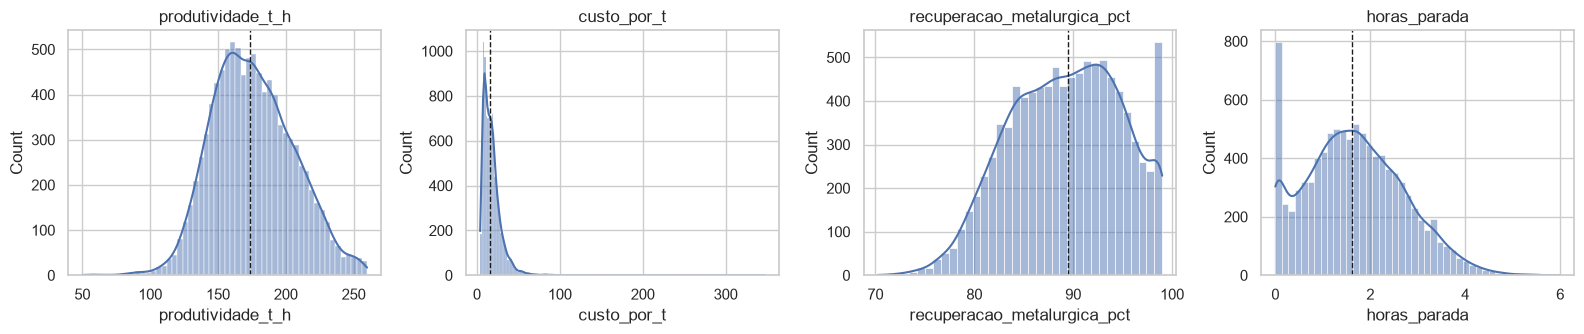

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, v in zip(axes, ['produtividade_t_h', 'custo_por_t', 'recuperacao_metalurgica_pct', 'horas_parada']):
    sns.histplot(df[v].dropna(), kde=True, ax=ax)
    ax.axvline(df[v].median(), color='k', ls='--', lw=1)
    ax.set_title(v)
plt.tight_layout(); plt.show()

**Interpretação e decisão**

- **Produtividade:** mediana de 174 t/h, CV de 17%, distribuição quase simétrica. A média descreve bem o centro.
- **Custo por tonelada:** mediana de R$ 15,57/t, mas média de R$ 17,93/t, assimetria 5,7 e curtose 101. Existe uma cauda longa: poucas operações com pouco produto e custo alto. Para essa variável, **reportar mediana e IQR, não média**.
- **Recuperação metalúrgica:** 89,3% em média, com pouca dispersão (CV de 6%).
- **Falhas:** a maioria das operações tem 0 ou 1 falha; o p95 é 2 falhas.
- **Status:** 73% normal, 27% com restrição e só 14 operações críticas (0,14%). A classe crítica é rara demais para um modelo próprio.

### 3.3 Estatística por grupos [E 14]

Médias agregadas podem esconder diferenças entre grupos. Comparar por turno, mina e tipo de minério antes de testar.

In [10]:
for g in ['turno', 'mina', 'tipo_minerio']:
    display(df.groupby(g)[['produtividade_t_h', 'custo_por_t', 'recuperacao_metalurgica_pct',
                           'qtd_falhas_equipamento', 'operacao_com_restricao']]
              .agg(['mean', 'median']).round(2))

produtividade_t_h         custo_por_t         \
                   mean  median        mean median   
turno                                                
Manhã           182.970 181.270      16.600 14.290   
Noite           165.530 163.290      19.980 17.420   
Tarde           176.010 173.630      17.810 15.490   

      recuperacao_metalurgica_pct        qtd_falhas_equipamento         \
                             mean median                   mean median   
turno                                                                    
Manhã                      89.290 89.600                  0.880  1.000   
Noite                      89.180 89.370                  1.110  1.000   
Tarde                      89.360 89.540                  0.960  1.000   

      operacao_com_restricao         
                        mean median  
turno                                
Manhã                  0.210  0.000  
Noite                  0.370  0.000  
Tarde                  0.260  0.000

produtividade_t_h         custo_por_t         \
                              mean  median        mean median   
mina                                                            
Mina Azul                  175.430 174.020      18.360 15.840   
Mina Brucutu               175.290 174.120      17.860 15.520   
Mina Catalão               175.430 172.580      18.050 15.830   
Mina Corumbá               177.180 174.970      17.380 15.050   
Mina Itabira               176.180 174.340      17.920 15.560   
Mina Serra Norte           175.660 173.300      17.990 15.740   

                 recuperacao_metalurgica_pct        qtd_falhas_equipamento  \
                                        mean median                   mean   
mina                                                                         
Mina Azul                             89.200 89.400                  0.990   
Mina Brucutu                          89.340 89.500                  0.960   
Mina Catalão                          89.450 89.840                  0.980   
Mina Corumbá                          89.360 89.700                  0.930   
Mina Itabira                          89.160 89.460                  0.980   
Mina Serra Norte                      89.220 89.320                  0.980   

                        operacao_com_restricao         
                 median                   mean median  
mina                                                   
Mina Azul         1.000                  0.280  0.000  
Mina Brucutu      1.000                  0.260  0.000  
Mina Catalão      1.000                  0.280  0.000  
Mina Corumbá      1.000                  0.250  0.000  
Mina Itabira      1.000                  0.270  0.000  
Mina Serra Norte  1.000                  0.280  0.000

produtividade_t_h         custo_por_t         \
                           mean  median        mean median   
tipo_minerio                                                 
Hematita                175.730 173.540      17.110 14.830   
Itabirito               175.840 173.840      19.000 16.400   
Magnetita               175.940 174.000      17.570 15.590   
Minério misto           175.970 173.440      18.290 15.890   

              recuperacao_metalurgica_pct        qtd_falhas_equipamento  \
                                     mean median                   mean   
tipo_minerio                                                              
Hematita                           93.780 93.970                  0.960   
Itabirito                          83.990 84.030                  0.970   
Magnetita                          91.050 91.120                  1.000   
Minério misto                      86.940 86.960                  0.960   

                     operacao_com_restricao         
              median                   mean median  
tipo_minerio                                        
Hematita       1.000                  0.270  0.000  
Itabirito      1.000                  0.270  0.000  
Magnetita      1.000                  0.280  0.000  
Minério misto  1.000                  0.260  0.000

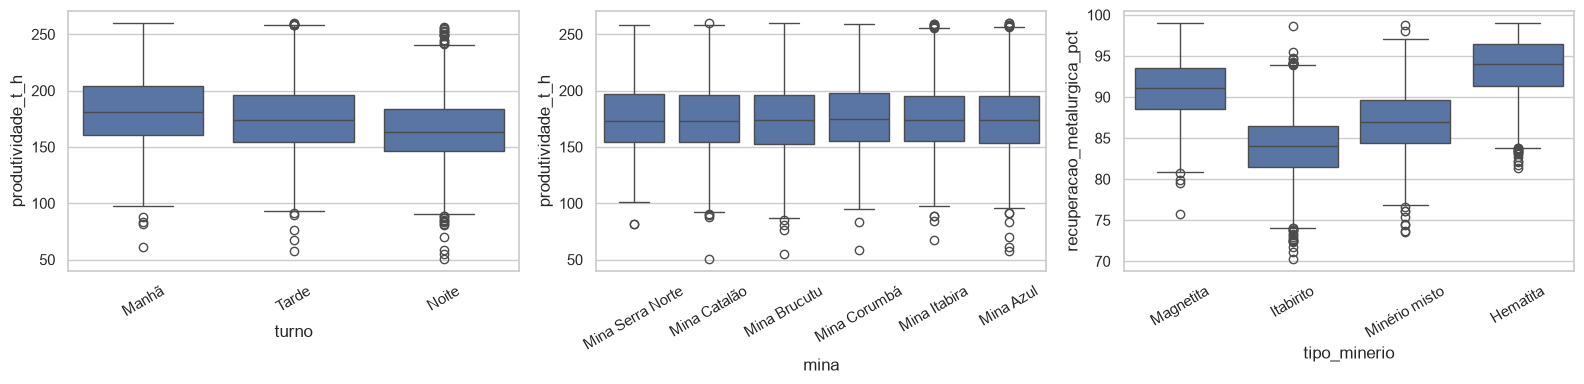

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.boxplot(data=df, x='turno', y='produtividade_t_h', order=['Manhã', 'Tarde', 'Noite'], ax=axes[0])
sns.boxplot(data=df, x='mina', y='produtividade_t_h', ax=axes[1])
sns.boxplot(data=df, x='tipo_minerio', y='recuperacao_metalurgica_pct', ax=axes[2])
for ax in axes: ax.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

**Interpretação e decisão**

O turno muda a produtividade: manhã 183 t/h, tarde 176 t/h e noite 166 t/h. A noite também tem mais falhas (1,11 contra 0,88 de manhã) e mais restrições (37% contra 21%).

Mina e tipo de minério praticamente não mudam a produtividade: as médias ficam entre 175 e 177 t/h. Já o tipo de minério muda muito a recuperação metalúrgica: hematita 93,8% e itabirito 84,0%. Próximo passo: confirmar essas diferenças com testes.

**Parte inferencial:** as diferenças vistas acima são reais ou acaso? E de que tamanho são?

Nível de significância α = 0,05. Com quase 10 mil linhas, quase tudo vira "significativo". A decisão usa **p-valor + tamanho do efeito + relevância prática** [E 23].

### 3.4 P2 – Proporção de operação crítica (evento raro) [E 22]

Intervalo de Wilson: adequado para proporções pequenas, onde o intervalo normal falha.

In [12]:
n = len(df)
for status in df['status_operacao'].unique():
    k = (df['status_operacao'] == status).sum()
    li, ls = proportion_confint(k, n, alpha=0.05, method='wilson')
    print(f'{status:24s} {k:5d}  p = {k/n*100:6.3f}%   IC95% Wilson = [{li*100:.3f}%, {ls*100:.3f}%]')

Operação normal           7186  p = 72.954%   IC95% Wilson = [72.068%, 73.822%]
Operação com restrição    2650  p = 26.904%   IC95% Wilson = [26.037%, 27.788%]
Operação crítica            14  p =  0.142%   IC95% Wilson = [0.085%, 0.238%]


**Interpretação e decisão**

A operação crítica acontece em 0,14% das operações, com IC95% de 0,09% a 0,24%: cerca de **1 em cada 700 operações**. O intervalo de Wilson é assimétrico, como deve ser perto de zero. Com só 14 casos, qualquer modelo para prever operação crítica teria pouquíssimos exemplos. A pergunta sobre esses casos fica para a detecção de anomalias (seção 4.7).

### 3.5 P3 – Produtividade entre turnos [E 24, E 33, E 34, E 35, E 27]

1. Levene (Brown-Forsythe, mediana) verifica se as variâncias são iguais.
2. ANOVA de Welch não exige variâncias iguais. Kruskal-Wallis confirma sem supor normalidade.
3. Pós-teste: Welch para cada par, com correção de Holm para comparações múltiplas.
4. Tamanho do efeito: diferença em t/h e Hedges g.

In [13]:
def hedges_g(a, b):
    a, b = np.asarray(a), np.asarray(b)
    na, nb = len(a), len(b)
    sp = np.sqrt(((na - 1) * a.var(ddof=1) + (nb - 1) * b.var(ddof=1)) / (na + nb - 2))
    return (a.mean() - b.mean()) / sp * (1 - 3 / (4 * (na + nb) - 9))

turnos = ['Manhã', 'Tarde', 'Noite']
grupos = [df.loc[df['turno'] == t, 'produtividade_t_h'].dropna() for t in turnos]
print('Levene (mediana):', stats.levene(*grupos, center='median'))
print('ANOVA de Welch  :', anova_oneway(grupos, use_var='unequal'))
print('Kruskal-Wallis  :', stats.kruskal(*grupos))

linhas = []
for i in range(3):
    for j in range(i + 1, 3):
        a, b = grupos[i], grupos[j]
        linhas.append({'par': f'{turnos[i]} x {turnos[j]}', 'dif_media_t_h': a.mean() - b.mean(),
                       'p_welch': stats.ttest_ind(a, b, equal_var=False).pvalue,
                       'hedges_g': hedges_g(a, b)})
pos = pd.DataFrame(linhas)
pos['p_holm'] = multipletests(pos['p_welch'], method='holm')[1]
pos

Levene (mediana): LeveneResult(statistic=np.float64(9.046584848019899), pvalue=np.float64(0.00011877450442379636))
ANOVA de Welch  : AnovaResult(statistic=np.float64(283.7564902328013), pvalue=np.float64(1.0409345964216985e-118), df=(2.0, np.float64(6283.375423399806)), df_num=2.0, df_denom=np.float64(6283.375423399806), nobs_total=np.float64(9850.0), n_groups=3, means=array([182.96977474, 176.01068493, 165.52697746]), nobs=array([3729., 3504., 2617.]), vars_=array([871.82176154, 873.42879399, 793.63026039]), use_var='unequal', welch_correction=True, df2=None, df_num2=None, pvalue2=None)
Kruskal-Wallis  : KruskalResult(statistic=np.float64(504.71668437819045), pvalue=np.float64(2.5244369310351183e-110))


,par,dif_media_t_h,p_welch,hedges_g,p_holm
0,Manhã x Tarde,6.959,0.000,0.236,0.000
1,Manhã x Noite,17.443,0.000,0.602,0.000
2,Tarde x Noite,10.484,0.000,0.362,0.000


**Interpretação e decisão**

Levene rejeita variâncias iguais (p = 0,0001), por isso a ANOVA de Welch foi usada. Welch e Kruskal-Wallis concordam: **o turno afeta a produtividade** (p < 1e-100).

Todas as diferenças entre pares continuam significativas depois da correção de Holm. O que importa é o tamanho:
- manhã x noite: **+17,4 t/h** (g = 0,60, efeito médio);
- tarde x noite: +10,5 t/h (g = 0,36);
- manhã x tarde: +7,0 t/h (g = 0,24, efeito pequeno).

**Decisão:** em uma operação de 9 horas, 17 t/h equivalem a cerca de 157 t por operação. O turno da noite é o maior ponto de melhoria encontrado. Investigar iluminação, fadiga e manutenção noturna.

### 3.6 P4 – Produtividade entre minas [E 35]

In [14]:
grupos_mina = [g['produtividade_t_h'].dropna() for _, g in df.groupby('mina')]
print('Kruskal-Wallis:', stats.kruskal(*grupos_mina))
print('ANOVA de Welch:', anova_oneway(grupos_mina, use_var='unequal'))
amp = df.groupby('mina')['produtividade_t_h'].mean()
print(f'Maior diferença entre médias de minas: {amp.max() - amp.min():.2f} t/h')

Kruskal-Wallis: KruskalResult(statistic=np.float64(3.4692023255218167), pvalue=np.float64(0.6280527473854225))
ANOVA de Welch: AnovaResult(statistic=np.float64(0.9206142852913853), pvalue=np.float64(0.46631793057504567), df=(5.0, np.float64(4592.861556940134)), df_num=5.0, df_denom=np.float64(4592.861556940134), nobs_total=np.float64(9850.0), n_groups=6, means=array([175.42682064, 175.29065868, 175.43360099, 177.18131595,
       176.17898316, 175.6601827 ]), nobs=array([1667., 1670., 1619., 1649., 1603., 1642.]), vars_=array([908.48593238, 922.98346655, 891.37396731, 934.07817139,
       872.44654822, 863.12616353]), use_var='unequal', welch_correction=True, df2=None, df_num2=None, pvalue2=None)
Maior diferença entre médias de minas: 1.89 t/h


**Interpretação e decisão**

Kruskal-Wallis (p = 0,63) e Welch (p = 0,47) não encontram diferença entre minas. A maior distância entre médias é de só 1,9 t/h.

**Cuidado [E 23]:** não rejeitar H0 não prova que as minas são iguais. Mas, com 1.600 operações por mina, a diferença real provavelmente é pequena demais para importar na prática. A mina não é um bom critério para priorizar ações.

### 3.7 P5 – Custo por tonelada: operação normal x com restrição [E 26, E 27, E 28]

In [15]:
normal = df.loc[df['operacao_com_restricao'] == 0, 'custo_por_t'].dropna()
restr = df.loc[df['operacao_com_restricao'] == 1, 'custo_por_t'].dropna()
w = stats.ttest_ind(restr, normal, equal_var=False)
ic = w.confidence_interval()
print(f'Média normal = R$ {normal.mean():.2f}/t | com restrição = R$ {restr.mean():.2f}/t')
print(f'Diferença = R$ {restr.mean() - normal.mean():.2f}/t  IC95% [{ic.low:.2f}, {ic.high:.2f}]  p = {w.pvalue:.2e}')
print(f'Hedges g = {hedges_g(restr, normal):.2f}')
print('Mann-Whitney:', stats.mannwhitneyu(restr, normal))

Média normal = R$ 14.21/t | com restrição = R$ 27.95/t
Diferença = R$ 13.74/t  IC95% [13.12, 14.37]  p = 0.00e+00
Hedges g = 1.33
Mann-Whitney: MannwhitneyuResult(statistic=np.float64(16527962.0), pvalue=np.float64(0.0))


**Verificação de vazamento:** antes de usar `status_operacao` como alvo de um modelo, conferir como ele foi gerado.

In [16]:
pd.crosstab(df['qtd_falhas_equipamento'], df['status_operacao'], margins=True)

status_operacao,Operação com restrição,Operação crítica,Operação normal,All
qtd_falhas_equipamento,,,,
0,58,0,2996,3054
1,186,0,4190,4376
2,2112,0,0,2112
3,294,0,0,294
4,0,14,0,14
All,2650,14,7186,9850


**Interpretação e decisão**

Uma operação com restrição custa em média **R$ 13,74/t a mais** (R$ 27,95 contra R$ 14,21; IC95% de R$ 13,12 a R$ 14,37). Hedges g = 1,33 é um efeito grande. Mann-Whitney confirma o resultado sem depender da média, que é sensível à cauda.

**Achado importante (vazamento de dados):** a tabela cruzada mostra que o status é quase uma **regra das falhas**:
- 2 ou 3 falhas: sempre "com restrição";
- 4 falhas: sempre "crítica";
- 0 ou 1 falha: quase sempre "normal" (só 244 exceções).

Um modelo de ML que use `qtd_falhas_equipamento` para prever `status_operacao` vai acertar quase 100%, mas não aprende nada útil. Na etapa de ML, retirar falhas, custo de manutenção e custo operacional das entradas, ou mudar o alvo para algo que se conheça **antes** da operação.

### 3.8 P6 – Restrição depende de turno ou tipo de minério? [E 38]

Qui-quadrado de independência com V de Cramér (0 = sem associação, 1 = associação total).

In [17]:
def cramer(tab):
    chi2, p, gl, _ = stats.chi2_contingency(tab)
    v = np.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1)))
    return chi2, p, gl, v

for c in ['turno', 'tipo_minerio', 'mina']:
    tab = pd.crosstab(df[c], df['operacao_com_restricao'])
    chi2, p, gl, v = cramer(tab)
    taxa = (pd.crosstab(df[c], df['operacao_com_restricao'], normalize='index')[1] * 100).round(1)
    print(f'{c:13s} chi2 = {chi2:7.1f}  gl = {gl}  p = {p:.2e}  V de Cramér = {v:.3f}')
    print('   % com restrição:', taxa.to_dict())

turno         chi2 =   199.2  gl = 2  p = 5.45e-44  V de Cramér = 0.142
   % com restrição: {'Manhã': 21.0, 'Noite': 36.9, 'Tarde': 26.2}
tipo_minerio  chi2 =     1.2  gl = 3  p = 7.52e-01  V de Cramér = 0.011
   % com restrição: {'Hematita': 26.9, 'Itabirito': 27.3, 'Magnetita': 27.9, 'Minério misto': 26.2}
mina          chi2 =     6.1  gl = 5  p = 2.96e-01  V de Cramér = 0.025
   % com restrição: {'Mina Azul': 28.1, 'Mina Brucutu': 26.3, 'Mina Catalão': 28.2, 'Mina Corumbá': 25.1, 'Mina Itabira': 26.9, 'Mina Serra Norte': 27.6}


**Interpretação e decisão**

- **Turno x restrição:** associação significativa (p = 5e-44), com V de Cramér de 0,14 (associação fraca, mas real). A noite tem 36,9% de restrição, a manhã 21,0%.
- **Tipo de minério e mina:** sem associação (p = 0,75 e p = 0,30; V < 0,03).

**Conclusão:** a restrição vem de falha de equipamento, e a falha se concentra no turno da noite. Não depende do minério nem da mina.

### 3.9 P7 – Matriz de correlações de Spearman [E 43, E 44]

Spearman mede relação monotônica e é robusto a extremos. Valores |ρ| > 0,9 indicam redundância (variáveis que medem a mesma coisa).

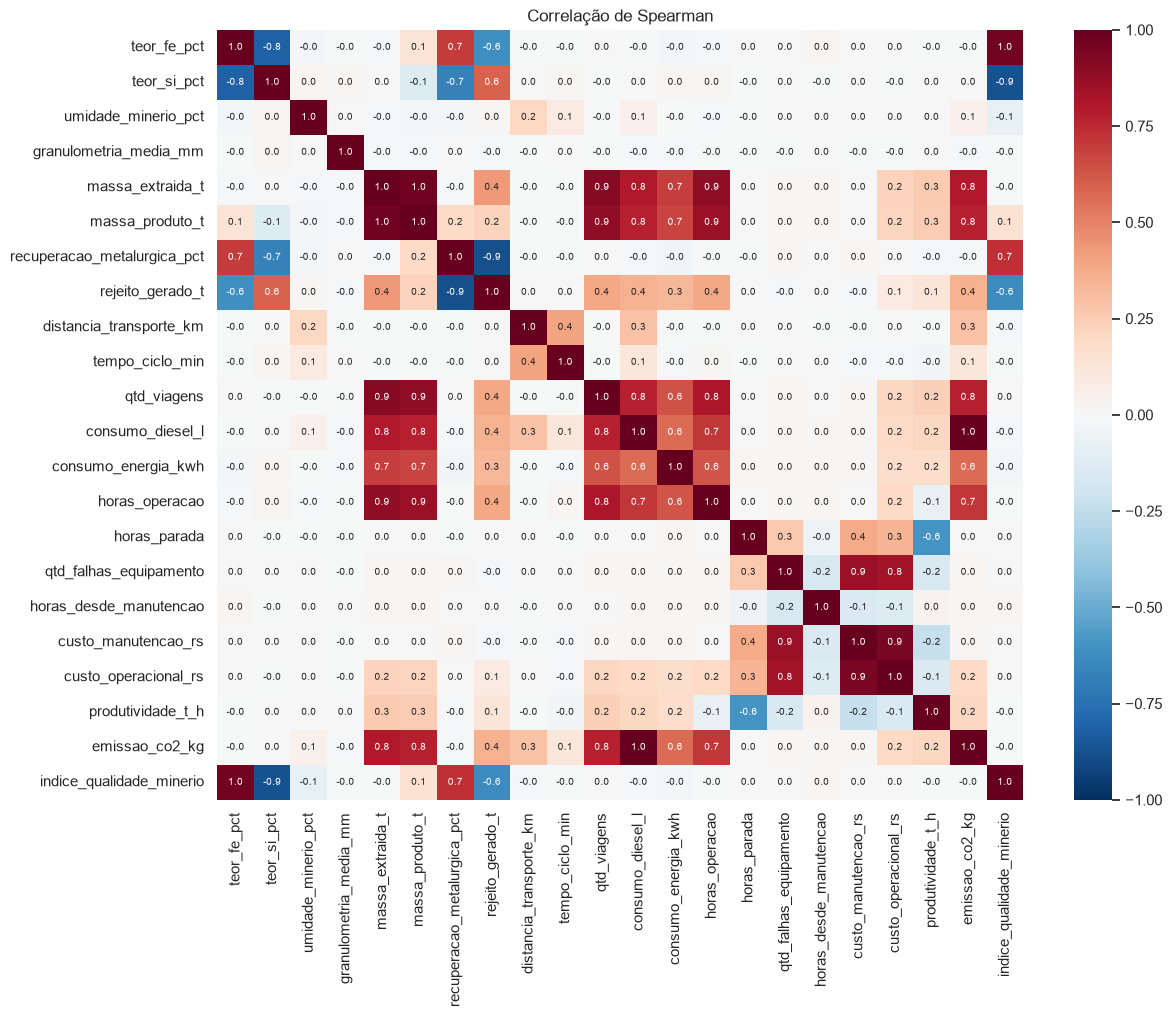

,,rho
consumo_diesel_l,emissao_co2_kg,1.000
massa_extraida_t,massa_produto_t,0.972
teor_fe_pct,indice_qualidade_minerio,0.968
custo_manutencao_rs,custo_operacional_rs,0.949
massa_extraida_t,qtd_viagens,0.911


In [18]:
NUM = ['teor_fe_pct', 'teor_si_pct', 'umidade_minerio_pct', 'granulometria_media_mm', 'massa_extraida_t',
       'massa_produto_t', 'recuperacao_metalurgica_pct', 'rejeito_gerado_t', 'distancia_transporte_km',
       'tempo_ciclo_min', 'qtd_viagens', 'consumo_diesel_l', 'consumo_energia_kwh', 'horas_operacao',
       'horas_parada', 'qtd_falhas_equipamento', 'horas_desde_manutencao', 'custo_manutencao_rs',
       'custo_operacional_rs', 'produtividade_t_h', 'emissao_co2_kg', 'indice_qualidade_minerio']
corr = df[NUM].corr(method='spearman')
plt.figure(figsize=(13, 10))
sns.heatmap(corr, cmap='RdBu_r', center=0, vmin=-1, vmax=1, annot=True, fmt='.1f', annot_kws={'size': 7})
plt.title('Correlação de Spearman'); plt.show()

pares = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack()
pares[pares.abs() > 0.9].sort_values(key=abs, ascending=False).to_frame('rho')

**Interpretação e decisão**

Pares redundantes (|ρ| > 0,9):
- diesel x CO2 (ρ = 1,00): o CO2 é calculado a partir do diesel;
- massa extraída x massa de produto (0,97);
- teor de Fe x índice de qualidade (0,97): o índice é praticamente o teor de Fe;
- custo de manutenção x custo operacional (0,95): o custo de manutenção é a maior parte do custo;
- massa extraída x viagens (0,91).

**Decisão:** em agrupamento e ML, usar só uma variável de cada par. Isso evita contar a mesma informação duas vezes na distância. Outras relações fortes: falhas x custo (0,84) e recuperação x teor de Fe (0,70). A produtividade quase não se relaciona com a qualidade do minério; o que a derruba são as horas paradas (ρ = −0,59).

### 3.10 P8 – O que explica a recuperação metalúrgica? [E 46, E 47]

Regressão linear múltipla com tipo de minério como categoria. Erros padrão HC3 protegem contra heterocedasticidade.

In [19]:
m_rec = smf.ols('recuperacao_metalurgica_pct ~ teor_fe_pct + teor_si_pct + umidade_minerio_pct'
                ' + granulometria_media_mm + C(tipo_minerio)', data=df).fit(cov_type='HC3')
print(m_rec.summary().tables[0]); print(m_rec.summary().tables[1])

                                 OLS Regression Results                                
Dep. Variable:     recuperacao_metalurgica_pct   R-squared:                       0.573
Model:                                     OLS   Adj. R-squared:                  0.572
Method:                          Least Squares   F-statistic:                     1818.
Date:                         Fri, 09 Oct 2026   Prob (F-statistic):               0.00
Time:                                 20:26:27   Log-Likelihood:                -25450.
No. Observations:                         9376   AIC:                         5.092e+04
Df Residuals:                             9368   BIC:                         5.097e+04
Df Model:                                    7                                         
Covariance Type:                           HC3                                         
                                       coef    std err          z      P>|z|      [0.025      0.975]
-------------------

**Contraste [E 44]:** o mesmo teor de Fe sozinho, sem controlar o tipo de minério.

In [20]:
m_fe = smf.ols('recuperacao_metalurgica_pct ~ teor_fe_pct', data=df).fit(cov_type='HC3')
print(f"Só teor de Fe: coef = {m_fe.params['teor_fe_pct']:.3f} p.p. por p.p. de Fe, R² = {m_fe.rsquared:.3f}")
print(f"Com tipo de minério: coef = {m_rec.params['teor_fe_pct']:.3f}, p = {m_rec.pvalues['teor_fe_pct']:.3f}, R² = {m_rec.rsquared:.3f}")
display(df.groupby('tipo_minerio')[['teor_fe_pct', 'teor_si_pct', 'recuperacao_metalurgica_pct']].agg(['mean', 'std']).round(2))

Só teor de Fe: coef = 0.481 p.p. por p.p. de Fe, R² = 0.484
Com tipo de minério: coef = 0.013, p = 0.269, R² = 0.573


teor_fe_pct       teor_si_pct       recuperacao_metalurgica_pct  \
                     mean   std        mean   std                        mean   
tipo_minerio                                                                    
Hematita           64.550 3.190       4.420 2.520                      93.780   
Itabirito          47.100 3.290      17.040 2.800                      83.990   
Magnetita          58.070 3.270       9.580 2.770                      91.050   
Minério misto      53.080 3.190      12.020 2.850                      86.940   

                     
                std  
tipo_minerio         
Hematita      3.490  
Itabirito     3.730  
Magnetita     3.740  
Minério misto 3.820

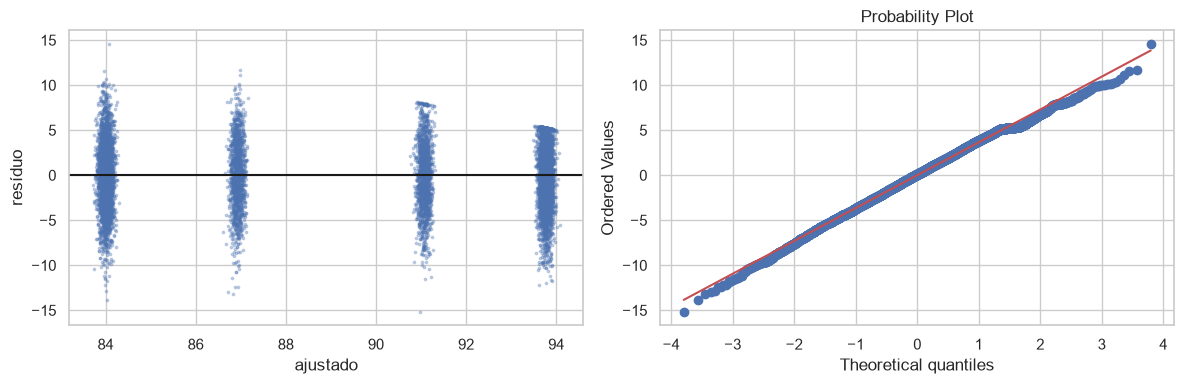

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(m_rec.fittedvalues, m_rec.resid, s=3, alpha=.3)
axes[0].axhline(0, color='k'); axes[0].set_xlabel('ajustado'); axes[0].set_ylabel('resíduo')
stats.probplot(m_rec.resid, plot=axes[1])
plt.tight_layout(); plt.show()

**Interpretação e decisão**

O modelo explica 57% da variação da recuperação (R² = 0,573). **O que explica é o tipo de minério**, comparado com a hematita:
- itabirito: −9,7 p.p.;
- minério misto: −6,8 p.p.;
- magnetita: −2,7 p.p.

Com o tipo de minério no modelo, teor de Fe, teor de Si, umidade e granulometria **deixam de ser significativos** (p > 0,12).

**Associação condicionada [E 44]:** sozinho, o teor de Fe parece forte (+0,48 p.p. de recuperação por p.p. de Fe, R² = 0,48). Mas a tabela por tipo mostra que cada tipo de minério tem uma faixa própria de teor (hematita ≈ 65% de Fe, itabirito ≈ 47%). O teor de Fe só "carrega" a informação do tipo. Dentro do mesmo tipo, mais Fe não aumenta a recuperação.

**Decisão:** para planejar a recuperação na usina, o dado que importa é o tipo de minério da frente de lavra. Os resíduos são simétricos e sem padrão de funil, e o HC3 protege os erros padrão.

### 3.11 P9 – Horas desde a manutenção aumentam as falhas? [E 53]

Falhas são contagens (0, 1, 2, 3…), então o modelo adequado é Poisson. A razão de dispersão (Pearson χ²/gl) perto de 1 indica que Poisson é adequado; muito acima de 1 indica sobredispersão.

In [22]:
m_fal = smf.glm('qtd_falhas_equipamento ~ horas_desde_manutencao + C(turno) + horas_operacao',
                data=df, family=sm.families.Poisson()).fit()
print(m_fal.summary().tables[1])
print('Dispersão (Pearson chi2 / gl):', round(m_fal.pearson_chi2 / m_fal.df_resid, 3))
irr = np.exp(m_fal.params).to_frame('razao_de_taxas')
irr['efeito_%'] = (irr['razao_de_taxas'] - 1) * 100
irr

                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                  0.0815      0.040      2.024      0.043       0.003       0.160
C(turno)[T.Noite]          0.2176      0.026      8.510      0.000       0.168       0.268
C(turno)[T.Tarde]          0.0862      0.025      3.511      0.000       0.038       0.134
horas_desde_manutencao    -0.0027      0.000    -13.830      0.000      -0.003      -0.002
horas_operacao             0.0042      0.004      1.186      0.236      -0.003       0.011
Dispersão (Pearson chi2 / gl): 0.658


,razao_de_taxas,efeito_%
Intercept,1.085,8.489
C(turno)[T.Noite],1.243,24.312
C(turno)[T.Tarde],1.090,9.002
horas_desde_manutencao,0.997,-0.267
horas_operacao,1.004,0.421


In [23]:
faixas = pd.cut(df['horas_desde_manutencao'], [0, 50, 100, 150, 200, df['horas_desde_manutencao'].max()])
df.groupby(faixas, observed=True)[['qtd_falhas_equipamento', 'horas_parada', 'custo_manutencao_rs']].mean()

,qtd_falhas_equipamento,horas_parada,custo_manutencao_rs
horas_desde_manutencao,,,
"(0.0, 50.0]",1.144,1.718,"18,937.004"
"(50.0, 100.0]",1.002,1.667,"17,188.582"
"(100.0, 150.0]",0.906,1.654,"15,970.092"
"(150.0, 200.0]",0.777,1.592,"14,223.202"
"(200.0, 319.4]",0.592,1.544,"11,937.529"


**Interpretação e decisão**

- **Turno:** a noite tem **24% mais falhas** que a manhã (razão 1,24; IC exclui 1), e a tarde 9% mais. Isso confirma as seções 3.5 e 3.8.
- **Horas desde a manutenção:** o efeito é **negativo**. Cada hora a mais reduz a taxa de falhas em 0,27%; 100 horas reduzem cerca de 24%. As faixas confirmam: 1,14 falha logo após a manutenção (0–50 h) contra 0,59 depois de 200 h.
- **Dispersão:** 0,66. Os dados variam **menos** que o esperado em Poisson (subdispersão), então os erros padrão estão conservadores (largos demais).

**Interpretação:** é contraintuitivo esperar menos falha longe da manutenção. Hipóteses: (1) causalidade reversa: equipamentos que falham muito vão mais vezes para a manutenção, então sempre aparecem com poucas horas desde a última; (2) o campo pode registrar a manutenção corretiva feita por causa da falha. **Não usar este resultado para espaçar manutenções.** Antes, a empresa precisa confirmar como `horas_desde_manutencao` é registrado. Esta é uma pergunta para levar ao cliente.

### 3.12 P10 – A estimativa de diesel tem viés? [E 25]

Erro = diesel real − diesel estimado. Teste t de uma amostra contra 0.

In [24]:
erro = (df['consumo_diesel_l'] - df['consumo_diesel_estimado_l']).dropna()
t1 = stats.ttest_1samp(erro, 0)
ic = t1.confidence_interval()
print(f'Erro médio = {erro.mean():.2f} L  IC95% [{ic.low:.2f}, {ic.high:.2f}]  p = {t1.pvalue:.2e}')
print(f'Erro relativo médio = {(erro / df.loc[erro.index, "consumo_diesel_estimado_l"]).mean() * 100:.2f}%')
print(f'MAE = {erro.abs().mean():.2f} L | consumo médio = {df["consumo_diesel_l"].mean():.1f} L')

Erro médio = 0.65 L  IC95% [0.55, 0.76]  p = 4.66e-34
Erro relativo médio = 1.03%
MAE = 4.22 L | consumo médio = 103.4 L


**Interpretação e decisão**

A estimativa da empresa **subestima o diesel em 0,65 L por operação** (IC95% de 0,55 a 0,76 L; p < 1e-30), ou seja, 1,0% a menos. O erro absoluto típico é de 4,2 L em 103 L (4%).

**Relevância prática:** o viés é estatisticamente certo, mas pequeno. Em 16 operações por dia, 0,65 L viram cerca de 10 L/dia e 3.800 L/ano. Um ajuste simples (+1%) na estimativa já corrige o orçamento de combustível.

## 4. Agrupamento e técnicas não supervisionadas

Não supervisionado = o algoritmo **não recebe a resposta** (o rótulo). Ele procura sozinho grupos parecidos ou casos estranhos. Depois, o grupo interpreta o que foi encontrado.

**Observação:** regressão não é técnica não supervisionada (ela usa uma variável resposta). No material do professor ela fica na parte de estatística [E 45–53], por isso aparece no tópico 3 (seções 3.10 e 3.11).

### 4.1 Escolha de atributos e padronização [E 62, E 63]

**Noção de semelhança:** duas operações são parecidas se têm qualidade de minério, desempenho, falhas e custo parecidos. Identificadores (`registro_id`, `operador_id`, equipamentos) e variáveis redundantes (|ρ| > 0,9 na seção 3.9) ficam fora. Também ficam fora os rótulos `status_operacao`/`operacao_com_restricao`, usados só depois para interpretar.

Variáveis em escalas diferentes (R$ x %) distorcem a distância. Por isso padronizar (média 0, desvio 1). Ausentes (~1%) recebem a mediana.

In [25]:
ATRIB = ['teor_fe_pct', 'teor_si_pct', 'umidade_minerio_pct', 'recuperacao_metalurgica_pct',
         'produtividade_t_h', 'horas_parada', 'qtd_falhas_equipamento', 'custo_operacional_rs',
         'distancia_transporte_km', 'massa_produto_t']
X = df[ATRIB].fillna(df[ATRIB].median())
Z = StandardScaler().fit_transform(X)
Z.shape

(9850, 10)

### 4.2 PCA: redundância e visualização [E 64, E 65]

In [26]:
pca = PCA(random_state=SEED).fit(Z)
var = pd.Series(pca.explained_variance_ratio_, index=[f'PC{i+1}' for i in range(len(ATRIB))])
display(pd.DataFrame({'variancia_%': var * 100, 'acumulada_%': var.cumsum() * 100}).head(6))
pd.DataFrame(pca.components_[:3].T, index=ATRIB, columns=['PC1', 'PC2', 'PC3'])

,variancia_%,acumulada_%
PC1,25.010,25.010
PC2,21.995,47.005
PC3,14.120,61.125
PC4,12.023,73.148
PC5,8.613,81.761
PC6,7.965,89.726


,PC1,PC2,PC3
teor_fe_pct,0.578,-0.028,-0.094
teor_si_pct,-0.570,0.031,0.098
umidade_minerio_pct,-0.025,0.002,-0.021
recuperacao_metalurgica_pct,0.546,-0.021,-0.048
produtividade_t_h,0.017,-0.389,0.591
horas_parada,0.010,0.482,-0.344
qtd_falhas_equipamento,0.035,0.549,0.313
custo_operacional_rs,0.049,0.559,0.386
distancia_transporte_km,-0.005,0.010,-0.027
massa_produto_t,0.193,0.004,0.514


**Interpretação e decisão**

PC1 (25% da variância) é o eixo da **qualidade do minério**: teor de Fe e recuperação de um lado, sílica do outro. PC2 (22%) é o eixo da **falha**: falhas, horas paradas e custo sobem, produtividade cai. PC3 (14%) separa produtividade e massa de produto.

São necessários 6 componentes para 90% da variância. Os dados não se resumem a 2 dimensões, por isso o gráfico PCA da seção 4.4 é só uma visualização aproximada. Umidade e distância quase não pesam em PC1–PC3: variam de forma independente do resto.

### 4.3 K-means: escolher k [E 70, E 71, E 80]

Cotovelo (inércia), silhueta (maior é melhor), Davies-Bouldin (menor é melhor) e Calinski-Harabasz (maior é melhor).

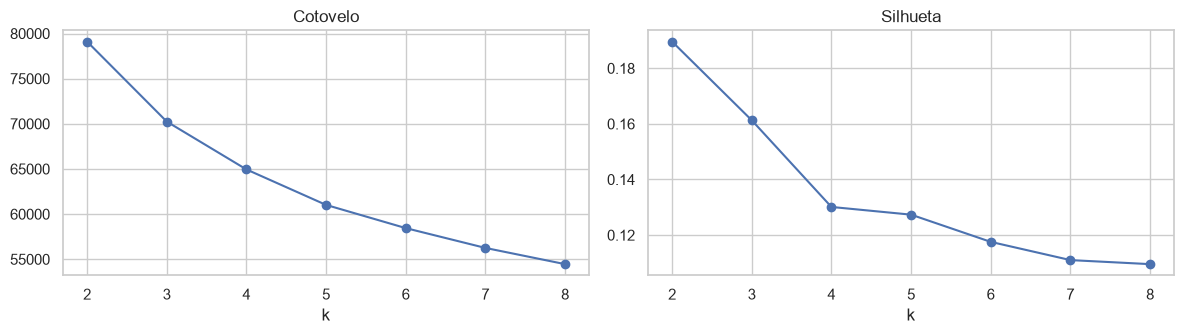

,inercia,silhueta,davies_bouldin,calinski_harabasz
k,,,,
2,"79,104.224",0.190,1.944,"2,414.660"
3,"70,246.029",0.161,1.852,"1,980.327"
4,"64,946.283",0.130,2.067,"1,695.628"
5,"61,016.705",0.127,2.004,"1,511.984"
6,"58,448.754",0.118,2.048,"1,349.114"
7,"56,253.087",0.111,2.040,"1,232.042"
8,"54,458.368",0.110,1.995,"1,137.066"


In [27]:
linhas = []
for k in range(2, 9):
    km = KMeans(k, n_init=10, random_state=SEED).fit(Z)
    linhas.append({'k': k, 'inercia': km.inertia_,
                   'silhueta': silhouette_score(Z, km.labels_, sample_size=4000, random_state=SEED),
                   'davies_bouldin': davies_bouldin_score(Z, km.labels_),
                   'calinski_harabasz': calinski_harabasz_score(Z, km.labels_)})
escolha_k = pd.DataFrame(linhas).set_index('k')
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
escolha_k['inercia'].plot(marker='o', ax=axes[0], title='Cotovelo')
escolha_k['silhueta'].plot(marker='o', ax=axes[1], title='Silhueta')
plt.tight_layout(); plt.show()
escolha_k

**Interpretação e decisão**

Todas as silhuetas são baixas (0,11 a 0,19). **Os grupos não são bem separados**: as operações formam uma nuvem contínua, não ilhas.

- Silhueta e Calinski-Harabasz preferem k = 2.
- Davies-Bouldin prefere k = 3 (1,85, o menor).
- O cotovelo não é nítido.

**Escolha: k = 3.** O índice Davies-Bouldin apoia, a perda de silhueta em relação a k = 2 é pequena (0,03), e os 3 perfis têm interpretação operacional clara (próxima célula). k = 2 junta "minério pobre" e "minério rico" e esconde a diferença de recuperação.

### 4.4 Perfis nas unidades originais e estabilidade [E 72, E 81]

In [28]:
K = 3
km = KMeans(K, n_init=10, random_state=SEED).fit(Z)
df['perfil'] = km.labels_
perfil = df.groupby('perfil')[ATRIB + ['custo_por_t', 'operacao_com_restricao']].mean().T
perfil.loc['n_operacoes'] = df['perfil'].value_counts().sort_index()
display(perfil)
display((pd.crosstab(df['perfil'], df['tipo_minerio'], normalize='index') * 100).round(1))

# Estabilidade: o agrupamento muda se trocarmos a semente?
rotulos = [KMeans(K, n_init=10, random_state=s).fit_predict(Z) for s in range(5)]
ari = [adjusted_rand_score(rotulos[0], r) for r in rotulos[1:]]
print('ARI entre sementes (1 = idêntico):', np.round(ari, 3))

perfil,0,1,2
teor_fe_pct,48.491,62.686,59.503
teor_si_pct,15.986,5.799,8.055
umidade_minerio_pct,9.619,9.411,9.490
recuperacao_metalurgica_pct,84.325,93.133,91.370
produtividade_t_h,177.603,186.379,158.583
horas_parada,1.533,1.222,2.493
qtd_falhas_equipamento,0.807,0.558,1.782
custo_operacional_rs,"23,259.689","19,729.107","40,058.095"
distancia_transporte_km,6.201,6.164,6.308
massa_produto_t,"1,467.231","1,662.029","1,648.789"


tipo_minerio,Hematita,Itabirito,Magnetita,Minério misto
perfil,,,,
0,0.100,75.200,4.100,20.700
1,71.400,0.100,22.900,5.600
2,50.200,10.900,24.000,15.000


ARI entre sementes (1 = idêntico): [0.998 0.928 0.962 0.998]


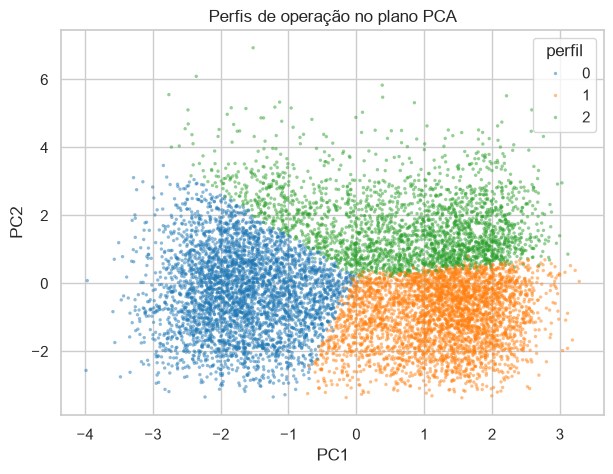

In [29]:
P = pca.transform(Z)[:, :2]
plt.figure(figsize=(7, 5))
sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=df['perfil'], palette='tab10', s=6, alpha=.5, linewidth=0)
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.title('Perfis de operação no plano PCA'); plt.show()

**Interpretação e decisão**

| Perfil | Nome sugerido | Características | Operações |
|---|---|---|---|
| 1 | **Minério rico e operação limpa** | 71% hematita, Fe 62,7%, recuperação 93,1%, 186 t/h, 0,56 falha, R$ 12,6/t, 5% com restrição | 3.525 |
| 0 | **Minério pobre** | 75% itabirito, Fe 48,5%, sílica 16%, recuperação 84,3%, 178 t/h, R$ 17,1/t | 3.796 |
| 2 | **Operação com falha** | qualquer minério, 1,78 falha, 2,5 h paradas, 159 t/h, R$ 26,5/t, 72% com restrição | 2.529 |

O agrupamento reencontrou, **sem receber o rótulo**, os dois fatores das seções anteriores: tipo de minério (qualidade e recuperação) e falha de equipamento (custo e restrição). O perfil 2 custa o dobro do perfil 1 por tonelada.

**Estabilidade:** o ARI entre sementes fica entre 0,93 e 1,00. Os grupos quase não mudam com a inicialização, então o resultado não é sorte do algoritmo.

### 4.5 P12 – Agrupamento hierárquico dos equipamentos [E 74]

Cada equipamento vira uma linha com médias de desempenho e desgaste. Com só 13 equipamentos, o dendrograma mostra quem se parece com quem.

,qtd_falhas_equipamento,horas_parada,custo_manutencao_rs,produtividade_t_h,tempo_ciclo_min
ESC-01,0.972,1.698,"17,027.237",174.788,34.881
ESC-02,0.980,1.645,"16,639.714",176.704,35.309
ESC-03,0.962,1.678,"16,980.436",175.476,35.146
ESC-04,0.954,1.656,"16,572.837",176.381,35.112
ESC-05,0.976,1.665,"16,577.435",176.045,35.034
CAM-101,0.977,1.652,"16,885.627",177.494,35.320
CAM-102,0.975,1.680,"16,767.434",176.027,35.385
CAM-103,0.941,1.657,"16,280.169",176.180,35.040
CAM-104,0.994,1.640,"17,197.387",176.111,34.822
CAM-105,0.952,1.700,"16,765.593",175.178,35.033


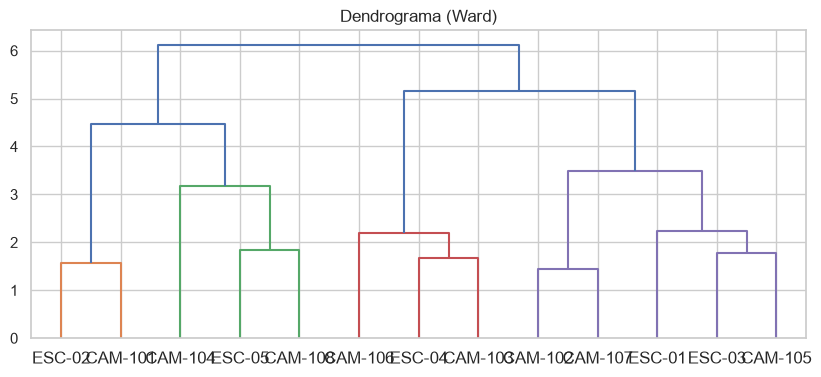

In [30]:
AT_EQ = ['qtd_falhas_equipamento', 'horas_parada', 'custo_manutencao_rs', 'produtividade_t_h', 'tempo_ciclo_min']
eq = pd.concat([df.groupby('equipamento_escavacao')[AT_EQ].mean(),
                df.groupby('equipamento_transporte')[AT_EQ].mean()])
display(eq)
L = linkage(StandardScaler().fit_transform(eq), method='ward')
plt.figure(figsize=(10, 4)); dendrogram(L, labels=eq.index.tolist()); plt.title('Dendrograma (Ward)'); plt.show()

**Interpretação e decisão**

Os 13 equipamentos são **praticamente iguais**. As falhas médias variam de 0,94 a 0,99 por operação, a produtividade de 175 a 177 t/h e o custo de manutenção de R$ 16,3 mil a R$ 17,2 mil. O dendrograma sempre agrupa alguma coisa, mas as alturas de junção vêm de diferenças minúsculas.

**Conclusão:** não existe um equipamento "problema" na média do período. O CAM-103 tem o menor nível de falha e o CAM-104 o maior, mas a distância entre eles (0,05 falha por operação) não justifica uma ação. A variação de falhas vem do turno, não da máquina.

### 4.6 P13 – Operadores: bons e pouco utilizados? (analogia do jogador)

O professor citou a análise de jogadores: um jogador bom, mas subaproveitado. Aqui o equivalente é um operador com produtividade alta e poucas falhas, mas com poucas operações.

**Cuidado:** cada operador tem poucas operações (ver distribuição abaixo). Média de 5 operações é instável. Por isso só entram operadores com pelo menos 8 operações, e a produtividade é comparada com a média do **mesmo turno** (turno afeta a produtividade, seção 3.5).

In [31]:
df['prod_vs_turno'] = df['produtividade_t_h'] - df.groupby('turno')['produtividade_t_h'].transform('mean')
op = df.groupby('operador_id').agg(n_operacoes=('registro_id', 'count'),
                                   prod_vs_turno=('prod_vs_turno', 'mean'),
                                   falhas_media=('qtd_falhas_equipamento', 'mean'),
                                   custo_por_t=('custo_por_t', 'median'))
print(op['n_operacoes'].describe().round(1))
op8 = op[op['n_operacoes'] >= 8].copy()
print('Operadores com >= 8 operações:', len(op8))

lim_prod = op8['prod_vs_turno'].quantile(.8)
lim_fal = op8['falhas_media'].quantile(.2)
mediana_n = op8['n_operacoes'].median()
subaproveitados = op8[(op8['prod_vs_turno'] >= lim_prod) & (op8['falhas_media'] <= lim_fal)
                      & (op8['n_operacoes'] <= mediana_n)].sort_values('prod_vs_turno', ascending=False)
print(f'Critério: produtividade >= p80 (+{lim_prod:.1f} t/h vs turno), falhas <= p20 ({lim_fal:.2f}), '
      f'operações <= mediana ({mediana_n:.0f})')
subaproveitados

count   1,497.000
mean        6.600
std         2.500
min         1.000
25%         5.000
50%         6.000
75%         8.000
max        17.000
Name: n_operacoes, dtype: float64
Operadores com >= 8 operações: 519
Critério: produtividade >= p80 (+7.9 t/h vs turno), falhas <= p20 (0.75), operações <= mediana (9)


,n_operacoes,prod_vs_turno,falhas_media,custo_por_t
operador_id,,,,
OP-1587,8,25.814,0.500,8.931
OP-2419,8,23.939,0.375,8.498
OP-1357,9,22.949,0.556,8.934
OP-1604,8,20.928,0.750,18.209
OP-1707,9,20.824,0.667,11.348
OP-1112,9,18.940,0.556,12.028
OP-2000,8,17.911,0.500,15.185
OP-2159,8,17.493,0.625,14.205
OP-1046,8,16.863,0.500,8.495


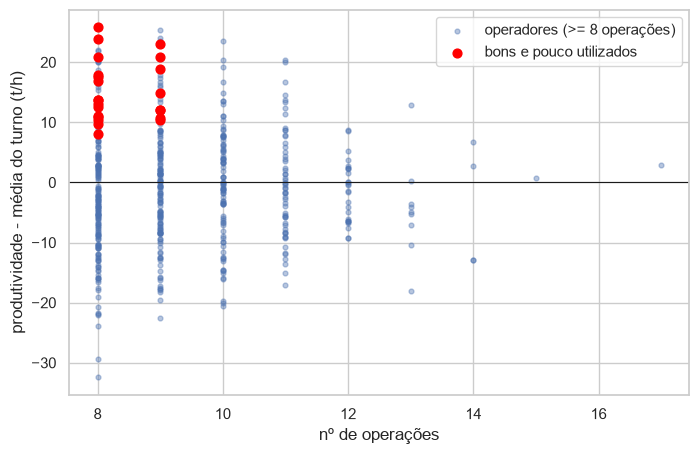

In [32]:
plt.figure(figsize=(8, 5))
plt.scatter(op8['n_operacoes'], op8['prod_vs_turno'], s=12, alpha=.4, label='operadores (>= 8 operações)')
plt.scatter(subaproveitados['n_operacoes'], subaproveitados['prod_vs_turno'], s=40, color='red', label='bons e pouco utilizados')
plt.axhline(0, color='k', lw=.8)
plt.xlabel('nº de operações'); plt.ylabel('produtividade - média do turno (t/h)'); plt.legend(); plt.show()

**Interpretação e decisão**

Com o critério "produtividade no top 20% do turno + falhas no menor 20% + operações até a mediana", foram encontrados **23 operadores** "bons e pouco utilizados" (de 519 com pelo menos 8 operações). Os 3 primeiros: OP-1587 (+25,8 t/h acima da média do turno), OP-2419 (+23,9) e OP-1357 (+22,9).

**Limites:** com 8 ou 9 operações por pessoa, parte desse destaque pode ser sorte. A escala também não é escolha do operador. **Decisão sugerida:** tratar a lista como candidatos e acompanhar esses operadores nas próximas semanas. Se mantiverem o desempenho com mais operações, aumentar a escala deles. É o mesmo raciocínio de observar um jogador antes de contratar.

Não é possível fazer série temporal por operador: com cerca de 6 operações em 20 meses, não há pontos suficientes.

### 4.7 P14 – Operações incomuns com Isolation Forest [E 85]

Isolation Forest pontua combinações raras de atributos. O resultado é uma lista de candidatos para investigar, não uma prova de erro.

In [33]:
iso = IsolationForest(contamination=0.01, random_state=SEED).fit(Z)
df['anomalia'] = iso.predict(Z) == -1
print('Operações marcadas:', df['anomalia'].sum())
comp = df.groupby('anomalia')[ATRIB + ['custo_por_t']].mean().T
comp.columns = ['normal', 'anômala']
display(comp)
print('Operações críticas entre as anômalas:',
      (df.loc[df['anomalia'], 'status_operacao'] == 'Operação crítica').sum(), 'de',
      (df['status_operacao'] == 'Operação crítica').sum())

Operações marcadas: 99


,normal,anômala
teor_fe_pct,56.403,55.408
teor_si_pct,10.300,11.455
umidade_minerio_pct,9.520,8.690
recuperacao_metalurgica_pct,89.295,88.392
produtividade_t_h,176.074,154.773
horas_parada,1.657,2.734
qtd_falhas_equipamento,0.953,2.444
custo_operacional_rs,"26,025.532","54,250.957"
distancia_transporte_km,6.218,5.977
massa_produto_t,"1,584.921","1,449.292"


Operações críticas entre as anômalas: 11 de 14


**Interpretação e decisão**

O Isolation Forest marcou 99 operações (1%). Em média elas têm 2,4 falhas, 2,7 h paradas, 155 t/h e custam **R$ 48,7/t, quase 3 vezes o normal**.

**Resultado forte:** sem receber o rótulo, o algoritmo encontrou **11 das 14 operações críticas**. Isso mostra que a operação crítica é de fato uma combinação rara de atributos. Um alerta automático baseado em anomalia captaria a maioria dos casos graves sem depender do campo `status_operacao`.

## 5. Conclusões do notebook 1


### 5.1 Objetivo

Este notebook explicou a Base 14 (mineração), com 9.850 operações de 01/2025 a 08/2026 em 6 minas, e mostrou a limpeza feita. Depois respondeu as perguntas P1 a P14 (seção 1.5) com estatística e agrupamento.

### 5.2 Principais resultados

| # | Pergunta | Resposta | Evidência |
|---|----------|----------|-----------|
| P3 | Turno muda a produtividade? | **Sim.** A noite rende 17 t/h a menos que a manhã | Welch e Kruskal p < 1e-100; Hedges g = 0,60 |
| P4 | Mina muda a produtividade? | Não, na prática | p = 0,63; diferença máxima de 1,9 t/h |
| P5 | Restrição encarece? | **Sim.** +R$ 13,74/t, quase o dobro | IC95% de R$ 13,12 a 14,37; g = 1,33 |
| P5 | O status é um bom alvo de ML? | **Não.** É uma regra direta de `qtd_falhas_equipamento` (vazamento) | Tabela cruzada |
| P6 | O que se associa à restrição? | Só o turno (noite 37% x manhã 21%) | χ² p = 5e-44; V = 0,14 |
| P8 | O que explica a recuperação? | **O tipo de minério** (hematita 93,8%, itabirito 84,0%). O teor de Fe só carrega essa informação | R² = 0,57; teor de Fe p = 0,27 com o tipo no modelo |
| P9 | Mais horas sem manutenção geram mais falhas? | Os dados mostram o contrário (−24% a cada 100 h). Provável causalidade reversa; **validar com a empresa** | Poisson; dispersão 0,66 |
| P10 | A estimativa de diesel tem viés? | Subestima 1% (0,65 L por operação) | t p < 1e-30 |
| P11 | Há perfis de operação? | 3 perfis: minério rico e operação limpa (R$ 12,6/t), minério pobre (R$ 17,1/t) e operação com falha (R$ 26,5/t) | K-means k = 3; ARI ≥ 0,93; silhueta baixa (0,16) |
| P12 | Algum equipamento destoa? | Não. Os 13 equipamentos são equivalentes | Hierárquico; falhas de 0,94 a 0,99 |
| P13 | Há operadores bons e pouco utilizados? | 23 candidatos, ainda com amostra pequena | Produtividade ajustada pelo turno |
| P14 | Dá para detectar casos graves sem rótulo? | **Sim.** O Isolation Forest achou 11 das 14 operações críticas | Contaminação de 1% |

### 5.3 Recomendações para a empresa

1. **Priorizar o turno da noite.** É o maior fator controlável: −17 t/h, +24% de falhas e +16 p.p. de restrição em relação à manhã. Investigar as causas: iluminação, fadiga, equipe de manutenção noturna.
2. **Reduzir falhas de equipamento.** Elas são a causa direta da restrição e dobram o custo por tonelada.
3. **Planejar a usina pelo tipo de minério**, não pelo teor isolado. Uma frente de itabirito perde cerca de 10 p.p. de recuperação.
4. **Revisar a forma de registrar `horas_desde_manutencao`** antes de usar esse campo para planejar manutenção.
5. **Ajustar a estimativa de diesel em +1%.**
6. **Usar o Isolation Forest como alerta precoce** de operações fora do padrão.

### 5.4 Limitações

- As operações não são totalmente independentes: o mesmo equipamento e a mesma mina se repetem (pseudorreplicação). Por isso a conclusão se apoia nos tamanhos de efeito, não só no p-valor.
- A base tem forte cara de dados simulados: as distribuições são muito regulares, e os equipamentos são idênticos. Os métodos estão corretos e prontos para dados reais, mas as conclusões numéricas valem só para esta base.

### 5.5 Próximos passos (etapa de machine learning)

- **Alvo sem vazamento:** prever `operacao_com_restricao` ou falhas **sem** usar falhas e custos como entrada. Usar só o que se sabe antes da operação: turno, tipo de minério, mina, frente, equipamento, horas desde a manutenção, distância.
- Classificação com regressão logística como referência, depois árvores e Random Forest. Validação cronológica e métricas para classe desbalanceada (recall, F1, AUC-PR).
- Regressão da recuperação metalúrgica e do custo por tonelada.
- Redes neurais e deep learning só se os modelos acima não responderem. Pelos resultados até aqui, a estrutura dos dados é simples e não deve exigir isso.

**Continua no notebook 2:** análise da produtividade ao longo do tempo (tópico 5).